# WESAD single-subject exploration: S2

**Jillian Melbourne** · HSE.751, Fall 2026

This notebook looks at one participant (S2) in depth before scaling up to all 15. It covers:
1. Dataset selection
2. Dataset Exploration
3. Target variable
4. Predictor variables
5. Descriptive statistics
6. Exploratory visualizations
7. Data quality notes
8. Summary

**Data:** `data/raw/S2/S2.pkl` from the UCI WESAD download. In Colab, upload or mount the folder and set `DATA_DIR` in the first code cell.

## Dataset selection

**Dataset:** WESAD (Wearable Stress and Affect Detection)
**Source:** UC Irvine Machine Learning Repository, https://archive.ics.uci.edu/dataset/465/wesad+wearable+stress+and+affect+detection

**Why I selected it.** My background is in signal processing for deep brain stimulation and wearables, so WESAD feels like familiar territory with new tools. It contains chest (ECG, EDA, respiration, temperature, EMG, acceleration) and wrist (blood volume pulse, EDA, temperature, acceleration) recordings from 15 participants during a lab stress protocol. Stress is hard to measure beyond self-report yet has major health effects, and wearables offer a promising way to quantify it passively. This project lets me build a complete pipeline from raw signal processing through model evaluation.

| Requirement | Met? | How WESAD meets it |
|---|---|---|
| Binary classification | ✅ | Stress (study label 2) vs. non-stress (baseline + amusement, labels 1 and 3) |
| ≥ 300 observations | ✅ | Each observation is a 60-second window; ~65 per participant × 15 participants ≈ 1,000 |
| ≥ 10 predictors | ✅ | Features engineered per window from both devices (heart rate, HRV, EDA, breathing rate, skin temperature, movement)

## Dataset Exploration

S2 is a 27-year-old right-handed man (wrist sensor on the left). His protocol order was baseline → stress → meditation → amusement → meditation.

**Dataset structure.** One pickle holds 10 signal arrays plus a label array, with no missing values. The chest arrays have 4,255,300 rows at 700 Hz. The wrist arrays have between 24,316 rows (EDA and temperature, 4 Hz) and 389,056 rows (BVP, 64 Hz). Every array works out to the same **6,079 s (1 h 41 min 19 s)**, because the authors trimmed both devices to the same synced span. There is no timestamp column; time = row number ÷ sampling rate.

**Target variable.** The `label` array codes the protocol condition at 700 Hz. The binary target is stress (label 2) vs. non-stress (baseline 1 + amusement 3). 

**Predictor variables.** There are six chest signals (ECG, EDA, respiration, temperature, EMG, 3-axis acceleration) and four wrist signals (BVP, EDA, temperature, 3-axis acceleration). Each window is summarized into 12 predictors:
- chest and wrist heart rate
- heart rate variability (RMSSD)
- chest and wrist EDA level
- EDA slope
- count of skin conductance responses
- breathing rate
- chest and wrist temperature
- movement variability on each device


## Data Quality Assessment
- **Participant-specific data quality issues** Each participant has specific data quality issues outlined in the readme. For this individuals specifically their chest temperature is unreliable. 
- **Signal vs noise.** Noise is very common in wearable datasets. This dataset is nice because there are some redundant measurements between the wrist and the chest monitors that may supplement each other when one is unreliable. 
- **Potential class imbalance.** More time in the session is spent at baseline and amusement than in the stress condition. 
- **Anticipated pre-processing steps.** Anticipated preprocessing steps involve applying high and low pass filters, chunking data into 60 second windows and generating features for predictors in downstream models.

## Project Planning
- **Proposed prediction problem:** Detect physiological stress from wearable sensor data. Using chest (RespiBAN) and wrist (Empatica E4) recordings from the 15 WESAD participants, predict whether a person was under stress during a given 60-second window, using features engineered from heart rate, HRV, EDA, respiration, skin temperature, and movement.
- **Target variable:** Binary stress, where 1 is the Trier Social Stress Test period (WESAD label 2) and 0 is non-stress (baseline and amusement, labels 1 and 3). Transitions, meditation, and "ignore" periods are excluded. Each observation is one 60-second window (30-second step), giving roughly 1,000 windows across all participants.
- **Candidate evaluation metrics:** F1 score on the stress class as the primary metric, with AUROC and balanced accuracy as supporting metrics. Stress is a minority of the usable time, so accuracy would be misleading. Models would be evaluated with leave-one-subject-out cross-validation, because overlapping windows from the same person would otherwise leak between training and test sets and inflate performance.

## 0. Setup

In [ ]:
# imports
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

# constants
SUBJECT = "S2"
DATA_DIR = Path("data/raw")       # folder that contains S2/S2.pkl

# define sampling rates
FS_CHEST = 700                    # every chest signal AND the label are sampled at 700 Hz
FS_WRIST = {"ACC": 32, "BVP": 64, "EDA": 4, "TEMP": 4}

# units for axes labels 
UNITS = {"ACC": "g", "ECG": "mV", "EMG": "mV", "EDA": "µS", "Temp": "°C", "Resp": "%",
         "BVP": "a.u.", "TEMP": "°C"}

# define label names and colors for plotting
LABEL_NAMES = {0: "transient", 1: "baseline", 2: "stress", 3: "amusement", 4: "meditation",
               5: "ignore", 6: "ignore", 7: "ignore"}
COLORS = {1: "#9db4c0", 2: "#e07a5f", 3: "#81b29a", 4: "#c9b6e4"}

# display settings 
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

# load the data 
with open(DATA_DIR / SUBJECT / f"{SUBJECT}.pkl", "rb") as f:
    data = pickle.load(f, encoding="latin1")    # saved with Python 2, so latin1 is needed

# pull pieces out of nested dictionary structure 
chest = data["signal"]["chest"]
wrist = data["signal"]["wrist"]
label = np.asarray(data["label"]).ravel()
print("Loaded", data["subject"])

Loaded S2


## 1. Dataset structure

The pickle is a nested dictionary:

```
data
├── "subject"  → "S2"
├── "label"    → one condition code per chest sample (700 Hz)
└── "signal"
    ├── "chest" → ACC, ECG, EMG, EDA, Temp, Resp   (RespiBAN, all 700 Hz)
    └── "wrist" → ACC, BVP, EDA, TEMP              (Empatica E4, 4–64 Hz)
```

There is **no time column**. Time is implicit: `seconds = row number / sampling rate`. The dataset authors trimmed both devices so that row 0 of every array is the same moment. So arrays with very different row counts cover exactly the same span of time.

In [ ]:
rows = []
# loop through data types from various sensors and collect metadata for each channel
for device, chans in [("chest", chest), ("wrist", wrist)]:
    for ch, arr in chans.items():
        arr = np.asarray(arr)
        fs = FS_CHEST if device == "chest" else FS_WRIST[ch]
        rows.append({"device": device, "channel": ch, "shape": str(arr.shape), "dtype": str(arr.dtype),
                     "fs_Hz": fs, "duration_s": len(arr) / fs, "duration_min": len(arr) / fs / 60,
                     "units": UNITS[ch], "n_NaN": int(np.isnan(arr).sum())})
rows.append({"device": "label", "channel": "label", "shape": str(label.shape), "dtype": str(label.dtype),
             "fs_Hz": FS_CHEST, "duration_s": len(label) / FS_CHEST,
             "duration_min": len(label) / FS_CHEST / 60, "units": "code", "n_NaN": 0})
structure = pd.DataFrame(rows)
display(structure)

dur = len(label) / FS_CHEST
print(f"Recording length: {len(label):,} rows / {FS_CHEST} Hz = {dur:,.0f} s "
      f"= {int(dur // 3600)} h {int(dur % 3600 // 60)} min {int(dur % 60)} s")
print("Every signal has the same duration:", structure["duration_s"].round(3).nunique() == 1)

,device,channel,shape,dtype,fs_Hz,duration_s,duration_min,units,n_NaN
0,chest,ACC,"(4255300, 3)",float64,700,"6,079.000",101.317,g,0
1,chest,ECG,"(4255300, 1)",float64,700,"6,079.000",101.317,mV,0
2,chest,EMG,"(4255300, 1)",float64,700,"6,079.000",101.317,mV,0
3,chest,EDA,"(4255300, 1)",float64,700,"6,079.000",101.317,µS,0
4,chest,Temp,"(4255300, 1)",float32,700,"6,079.000",101.317,°C,0
5,chest,Resp,"(4255300, 1)",float64,700,"6,079.000",101.317,%,0
6,wrist,ACC,"(194528, 3)",float64,32,"6,079.000",101.317,g,0
7,wrist,BVP,"(389056, 1)",float64,64,"6,079.000",101.317,a.u.,0
8,wrist,EDA,"(24316, 1)",float64,4,"6,079.000",101.317,µS,0
9,wrist,TEMP,"(24316, 1)",float64,4,"6,079.000",101.317,°C,0


Recording length: 4,255,300 rows / 700 Hz = 6,079 s = 1 h 41 min 19 s
Every signal has the same duration: True


Build a time axis for every signal. Rows are **never deleted** from these arrays; selecting by condition is done with a mask (chest) or by mapping each wrist sample's time onto the 700 Hz label (wrist). That way every kept sample still carries its true time.

In [ ]:
# helper function that returns the time axis for a given number of samples and sampling rate
def time_axis(n, fs):
    return np.arange(n) / fs

# helper function that returns the label for each of n samples recorded at fs Hz
def label_at(n, fs):
    # Condition label for each of n samples recorded at fs Hz (looked up by time)
    idx = np.minimum((np.arange(n) * FS_CHEST / fs).astype(int), len(label) - 1)
    return label[idx]

# apply helper functions to create time axes and labels for each signal and confirm it worked 
t_chest = time_axis(len(label), FS_CHEST)
wrist_label = {k: label_at(len(v), FS_WRIST[k]) for k, v in wrist.items()}
print("Example: wrist EDA row 1,000 is at", 1000 / 4, "s; chest row", 1000 * 175,
      "is the same moment; label there =", label[1000 * 175], "/", wrist_label["EDA"][1000])

Example: wrist EDA row 1,000 is at 250.0 s; chest row 175000 is the same moment; label there = 0 / 0


## 2. Target variable

`label` records which part of the study protocol the participant was in. For the project, the binary target is:

| `stress` | WESAD label | Condition |
|---|---|---|
| **1** | 2 | Stress: Trier Social Stress Test (public speech + mental arithmetic) |
| **0** | 1, 3 | Baseline (reading magazines) and amusement (funny videos) |
| excluded | 0, 4, 5–7 | Transitions, meditation, and "ignore" periods |

In [13]:
counts = pd.Series(label).value_counts().sort_index()
# output a table with the number of minutes and percentage of recording for each condition, plus a binary target column
target_table = pd.DataFrame({
    "condition": [LABEL_NAMES[int(k)] for k in counts.index],
    "minutes": counts.values / FS_CHEST / 60,
    "% of recording": 100 * counts.values / len(label),
    "binary target": ["1 (stress)" if k == 2 else "0 (non-stress)" if k in (1, 3) else "excluded"
                      for k in counts.index]}, index=counts.index.rename("label"))
display(target_table)

# output how much of the recording is usable for the binary stress detection task (baseline, stress, amusement) and what share of that time is stress
usable = np.isin(label, [1, 2, 3])
print(f"Usable for the binary task: {usable.sum() / FS_CHEST / 60:.1f} min "
      f"({usable.mean():.0%} of the recording); "
      f"stress share of usable time = {(label == 2).sum() / usable.sum():.0%}")

,condition,minutes,% of recording,binary target
label,,,,
0,transient,51.017,50.354,excluded
1,baseline,19.067,18.819,0 (non-stress)
2,stress,10.250,10.117,1 (stress)
3,amusement,6.033,5.955,0 (non-stress)
4,meditation,12.800,12.634,excluded
6,ignore,1.083,1.069,excluded
7,ignore,1.067,1.053,excluded


Usable for the binary task: 35.4 min (35% of the recording); stress share of usable time = 29%


## 3. Predictor variables

### 3.1 Raw signals

| Device | Signal | Rate | What it measures | Expected stress response |
|---|---|---|---|---|
| Chest | ECG | 700 Hz | Electrical activity of the heart → heart rate and heart rate variability (HRV) | HR ↑, HRV ↓ |
| Chest | EDA | 700 Hz | Skin conductance (sweat gland activity, purely sympathetic) | ↑ level, more responses |
| Chest | Resp | 700 Hz | Chest expansion (piezo belt) → breathing rate and depth | faster, less regular (here also talking) |
| Chest | Temp | 700 Hz | Skin temperature on the chest | small changes; see quality notes |
| Chest | EMG | 700 Hz | Muscle activity (upper trapezius) | ↑ muscle tension |
| Chest | ACC | 700 Hz | 3-axis acceleration (g) → posture and movement | unknown: standing and talking |
| Wrist | BVP | 64 Hz | Blood volume pulse (optical PPG) → pulse rate | HR ↑; motion-sensitive |
| Wrist | EDA | 4 Hz | Skin conductance at the wrist | ↑ |
| Wrist | TEMP | 4 Hz | Skin temperature at the wrist | ↓ (peripheral vasoconstriction) |
| Wrist | ACC | 32 Hz | 3-axis acceleration (1/64 g) → hand/arm movement | unknown |

### Preprocessing : chunking and filtering data
A classifier needs one row per observation. Each row here is a **60-second window** (30-second step). I conducted this data cleaning for the purpose of visualization, but will be spending more time fine-tuning it prior to submitting 

In [14]:
# set window and step length - 60 second windows and 30 second steps (50% overlap) is a common choice for physiological signals
WINDOW_S, STEP_S = 60, 30

def sos(kind, cut, fs, order=4):
    """ Return second-order sections for a Butterworth filter of the given kind and cutoff frequency(ies).
    kind: 'low', 'high', 'band'
    cut: cutoff frequency (Hz) for 'low' or 'high', or [low, high] for 'band'
    fs: sampling frequency (Hz)
    order: filter order (default 4)"""
    return signal.butter(order, cut, btype=kind, fs=fs, output="sos")

def beats_to_hr(peaks, fs):
    """ Calculate heart rate and HRV from heartbeats. Heart rate is 60 dividied by mean IBI (inter-beat interval). HRV is RMSSD (root mean square of successive differences) of IBI.
    peaks: array of peak indices (heartbeats)
    fs: sampling frequency (Hz) of the signal from which peaks were detected"""
    ibi = np.diff(peaks) / fs # gaps between beats in seconds
    ibi = ibi[(ibi > 0.33) & (ibi < 1.5)]           # keep 40-180 bpm (physiologically plausible)
    if len(ibi) < 10: # not enough beats to calculate HRV
        return np.nan, np.nan
    return 60 / ibi.mean(), 1000 * np.sqrt(np.mean(np.diff(ibi) ** 2))   # HR (bpm), RMSSD (ms)

# Filter whole recordings 
ecg = signal.sosfiltfilt(sos("band", [5, 15], FS_CHEST), np.ravel(chest["ECG"])) # bandpass filter chest ECG at 5 to 15 Hz; np.ravel() converts 2D array to 1D; sosfilfilt runs the filter forward and backward to avoid phase distortion
ecg_energy = np.convolve(np.diff(ecg, prepend=ecg[0]) ** 2, np.ones(105) / 105, mode="same") # energy of ECG is the squared derivative, smoothed with a 150 ms moving average (105 samples at 700 Hz)
bvp = signal.sosfiltfilt(sos("band", [0.7, 3.5], 64, order=2), np.ravel(wrist["BVP"])) # bandpass filter wrist BVP at 0.7 to 3.5 Hz
resp = signal.sosfiltfilt(sos("band", [0.1, 0.7], 10, order=2), 
                          signal.sosfiltfilt(sos("low", 5, FS_CHEST), np.ravel(chest["Resp"]))[::70]) # bandpass filter chest Resp at 0.1 to 0.7 Hz; downsample to 10 Hz by taking every 70th sample after lowpass filtering at 5 Hz
chest_eda = signal.sosfiltfilt(sos("low", 1, FS_CHEST), np.ravel(chest["EDA"]))[::175]   # 4 Hz
wrist_eda = np.ravel(wrist["EDA"])
acc_c = np.linalg.norm(np.asarray(chest["ACC"], float), axis=1)
acc_w = np.linalg.norm(np.asarray(wrist["ACC"], float) / 64, axis=1)

def sl(x, fs, t0):
    """Helper function to slice a signal x sampled at fs Hz, starting at time t0 (in seconds) and returning a window of length WINDOW_S (in seconds)."""
    return x[int(t0 * fs): int((t0 + WINDOW_S) * fs)]

# loop over windows and extract features for each window, skipping windows that are not usable (not baseline, stress, or amusement)
rows = []
for t0 in np.arange(0, len(label) / FS_CHEST - WINDOW_S + 1e-9, STEP_S):
    lw = sl(label, FS_CHEST, t0)
    if len(np.unique(lw)) != 1 or lw[0] not in (1, 2, 3):
        continue
    e = sl(ecg_energy, FS_CHEST, t0)
    pk, _ = signal.find_peaks(e, distance=int(0.33 * FS_CHEST), height=0.3 * np.percentile(e, 99))
    b = sl(bvp, 64, t0)
    bpk, _ = signal.find_peaks(b, distance=int(0.33 * 64), prominence=0.3 * b.std())
    r = sl(resp, 10, t0)
    rpk, _ = signal.find_peaks(r, distance=15, prominence=0.3 * r.std())
    we = sl(wrist_eda, 4, t0)
    scr, _ = signal.find_peaks(we, prominence=0.01, distance=4)
    hr_c, rmssd_c = beats_to_hr(pk, FS_CHEST)
    hr_w, _ = beats_to_hr(bpk, 64)
    ce = sl(chest_eda, 4, t0)
    rows.append({
        "t_start_min": t0 / 60, "condition": LABEL_NAMES[int(lw[0])], "stress": int(lw[0] == 2),
        "chest_hr_bpm": hr_c, "chest_rmssd_ms": rmssd_c, "wrist_hr_bpm": hr_w,
        "chest_eda_uS": ce.mean(), "chest_eda_slope_uS_per_min": np.polyfit(np.arange(len(ce)) / 240, ce, 1)[0],
        "wrist_eda_uS": we.mean(), "wrist_scr_count": len(scr),
        "resp_rate_bpm": len(rpk) * 60 / WINDOW_S,
        "chest_temp_C": np.ravel(sl(chest["Temp"], FS_CHEST, t0)).mean(),
        "wrist_temp_C": np.ravel(sl(wrist["TEMP"], 4, t0)).mean(),
        "chest_acc_sd_g": sl(acc_c, FS_CHEST, t0).std(), "wrist_acc_sd_g": sl(acc_w, 32, t0).std()})
win = pd.DataFrame(rows)
FEATURES = [c for c in win.columns if c not in ("t_start_min", "condition", "stress")]
print(f"{len(win)} windows x {len(FEATURES)} predictors")
display(win.head())

65 windows x 12 predictors


,t_start_min,condition,stress,chest_hr_bpm,chest_rmssd_ms,wrist_hr_bpm,chest_eda_uS,chest_eda_slope_uS_per_min,wrist_eda_uS,wrist_scr_count,resp_rate_bpm,chest_temp_C,wrist_temp_C,chest_acc_sd_g,wrist_acc_sd_g
0,5.500,baseline,0,74.963,72.034,77.928,4.589,-0.789,1.112,14,21.000,29.065,35.759,0.023,0.085
1,6.000,baseline,0,70.963,55.659,77.064,4.189,-0.797,0.889,6,22.000,28.886,35.710,0.005,0.035
2,6.500,baseline,0,70.379,57.632,75.650,3.838,-0.606,0.701,4,22.000,28.809,35.728,0.004,0.022
3,7.000,baseline,0,73.937,68.696,77.995,3.548,-0.540,0.581,7,24.000,28.798,35.785,0.008,0.063
4,7.500,baseline,0,75.140,68.313,79.261,3.315,-0.399,0.513,11,23.000,28.800,35.832,0.009,0.081


## 4. Descriptive statistics

### 4.1 Raw signals by condition
Means and SDs of every raw sample, grouped by condition. Chest signals are grouped with the 700 Hz label directly. Wrist signals use each sample's label looked up by time.

In [15]:
CONDITION_ORDER = ["baseline", "amusement", "stress"]

summary = (win.groupby("condition")[FEATURES]
              .agg(["mean", "std"])      # NaNs are skipped automatically
              .loc[CONDITION_ORDER]      # fix the column order
              .T)                        # one row per feature/statistic

display(summary)
print("Windows per condition:")
display(win["condition"].value_counts().reindex(CONDITION_ORDER).to_frame("n_windows"))

condition                        baseline  amusement  stress
chest_hr_bpm               mean    72.054     66.327  76.017
                           std      1.918      1.499   2.644
chest_rmssd_ms             mean    65.568    107.531  80.374
                           std      8.550     39.706  53.769
wrist_hr_bpm               mean    76.033     75.517  81.612
                           std      3.622      4.285   4.593
chest_eda_uS               mean     1.973      0.757   1.767
                           std      0.945      0.069   0.582
chest_eda_slope_uS_per_min mean    -0.204     -0.032   0.182
                           std      0.219      0.090   0.202
wrist_eda_uS               mean     0.265      0.202   0.862
                           std      0.245      0.024   0.202
wrist_scr_count            mean     3.167      3.200   8.789
                           std      3.621      1.814   3.293
resp_rate_bpm              mean    21.222     20.700  18.000
                           std      1.416      1.337   3.127
chest_temp_C               mean    28.865     32.157  31.220
                           std      1.199      0.233   0.109
wrist_temp_C               mean    35.791     34.190  33.453
                           std      0.101      0.115   0.441
chest_acc_sd_g             mean     0.006      0.004   0.011
                           std      0.003      0.002   0.003
wrist_acc_sd_g             mean     0.036      0.023   0.034
                           std      0.022      0.011   0.026

Windows per condition:


,n_windows
condition,
baseline,36
amusement,10
stress,19


## 5. Exploratory visualizations

### Figure 1: Aligned session across multiple sensor modalities
Shaded bands are the labeled conditions; white gaps are transitions (label 0) or "ignore" periods.

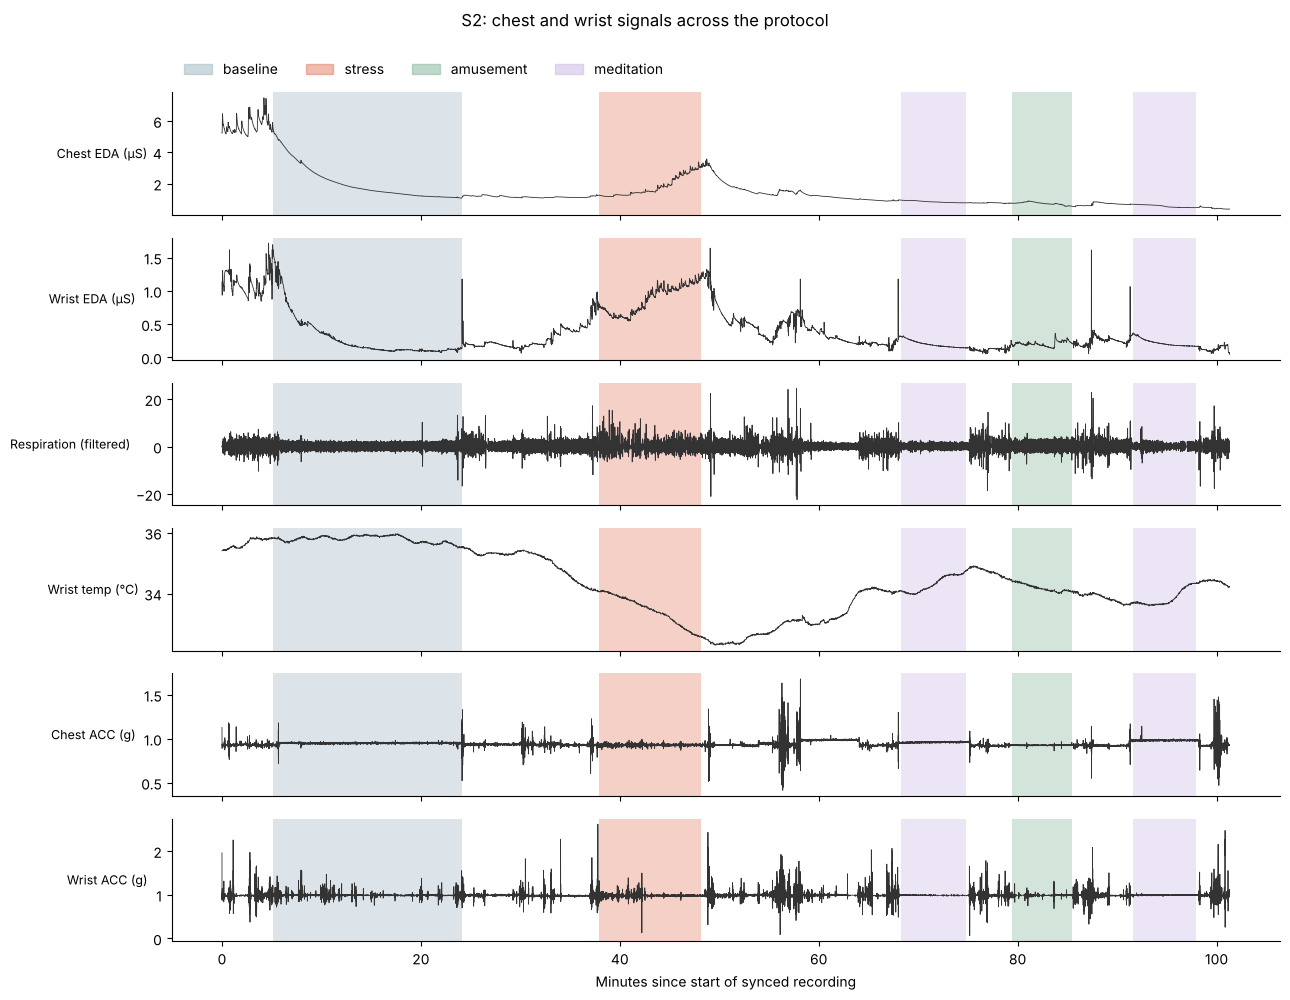

In [ ]:
def shade(ax, scale=60):
    """Shade the background of a plot by experimental condition.

    Args:
        ax: The matplotlib axes to shade.
        scale: Seconds per x-axis unit (60 = the x-axis is in minutes).
    """
    # `periods` has one row per contiguous condition block, with columns
    # start_min, end_min, and label. Keep only labels that have a color
    # (baseline, stress, amusement, meditation).
    for _, period in periods[periods["label"].isin(COLORS)].iterrows():
        # Convert minutes -> seconds (* 60) -> plot units (/ scale).
        # With the default scale=60 this leaves the values in minutes.
        ax.axvspan(period.start_min * 60 / scale, period.end_min * 60 / scale,
                   color=COLORS[period.label], alpha=0.35, lw=0)


# ---- Choose which signals to plot -------------------------------------------
# Each panel is (y-axis label, signal, sampling rate in Hz).
# The sampling rate is needed to build each panel's time axis.
panels = [
    ("Chest EDA (µS)",         chest_eda,                4),   # already downsampled to 4 Hz
    ("Wrist EDA (µS)",         wrist_eda,                4),   # natively 4 Hz
    ("Respiration (filtered)", resp,                     10),  # downsampled to 10 Hz earlier
    ("Wrist temp (°C)",        np.ravel(wrist["TEMP"]),  4),   # natively 4 Hz
    ("Chest ACC (g)",          acc_c[::175],             4),   # 700 Hz -> 4 Hz (every 175th sample)
    ("Wrist ACC (g)",          acc_w[::8],               4),   # 32 Hz -> 4 Hz (every 8th sample)
]

# ---- Create the figure ------------------------------------------------------
fig, axes = plt.subplots(len(panels), 1, figsize=(13, 10), sharex=True)

for ax, (name, y, fs) in zip(axes, panels):
    # Seconds -> minutes for the x-axis. Thin dark line keeps long signals readable.
    ax.plot(time_axis(len(y), fs) / 60, y, lw=0.6, color="#333")

    shade(ax)  # colored condition bands behind the line

    # Horizontal label to the left of the panel, so long names stay readable.
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)

# ---- Legend, axis label, title ----------------------------------------------
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.5) for c in COLORS.values()]

# Place the legend just above the top panel (bbox_to_anchor y=1.02), in one row.
axes[0].legend(handles, [LABEL_NAMES[k] for k in COLORS], ncol=4, frameon=False,
               loc="lower left", bbox_to_anchor=(0, 1.02))

axes[-1].set_xlabel("Minutes since start of synced recording")
fig.suptitle(f"{SUBJECT}: chest and wrist signals across the protocol", y=0.995)

fig.tight_layout()  # prevent labels and panels from overlapping
plt.show()

### Figure 2: the same 10 seconds on both devices
One minute into baseline and one minute into stress. Each chest heartbeat (ECG) should be followed a fraction of a second later by a pulse at the wrist (BVP).

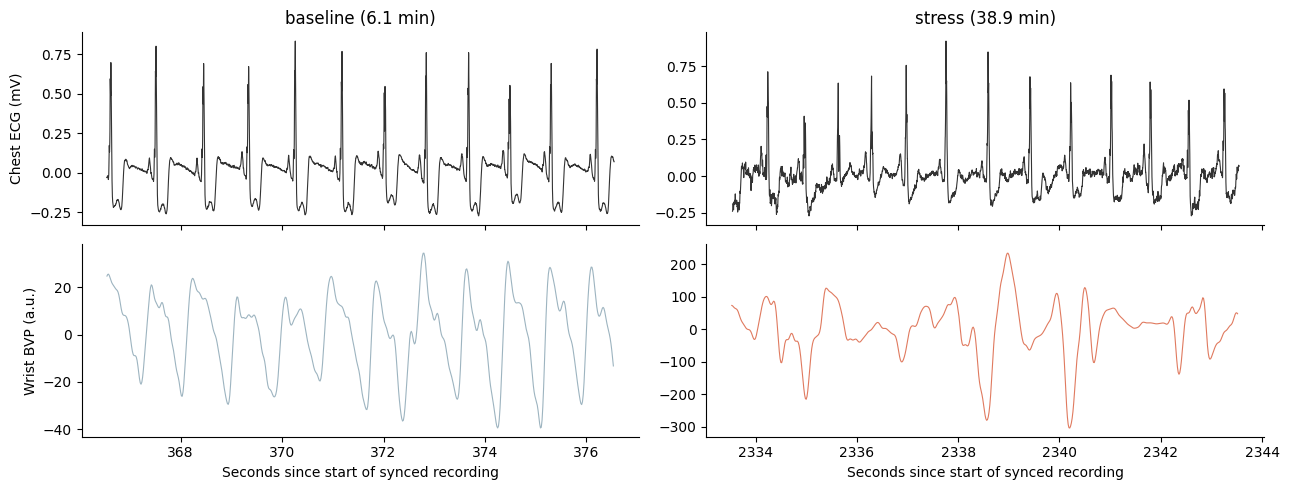

In [18]:
# Compare a 10-second snippet of ECG and BVP during baseline vs. stress.
# 
fig, axes = plt.subplots(2, 2, figsize=(13, 5), sharex="col")

# ---- One column per condition ----------------------------------------------
for col, lab in enumerate([1, 2]):          # 1 = baseline, 2 = stress

    # Start of the snippet: np.argmax on a boolean array returns the index of
    # the first True, i.e. the first sample of this condition. Look up its time
    # in seconds, then skip 60 s so the snippet comes from inside the
    # condition rather than its edge.
    t0 = t_chest[np.argmax(label == lab)] + 60

    # ---- One row per signal -------------------------------------------------
    # Each entry is (y-axis label, signal, sampling rate in Hz).
    signals = [("Chest ECG (mV)",   np.ravel(chest["ECG"]), FS_CHEST),
               ("Wrist BVP (a.u.)", np.ravel(wrist["BVP"]), 64)]

    for row, (name, x, fs) in enumerate(signals):
        # Convert the 10-second window (t0 to t0 + 10 s) into sample indices
        # for this signal's own sampling rate.
        start, stop = int(t0 * fs), int((t0 + 10) * fs)

        # Top row (ECG) is dark gray; bottom row (BVP) uses the condition color.
        # `row` is 0 or 1, so `if row` means "if this is the BVP row".
        color = COLORS[lab] if row else "#333"

        # Time axis is in absolute seconds, so the x-ticks show where the
        # snippet sits in the session, not 0-10.
        axes[row, col].plot(time_axis(len(x), fs)[start:stop], x[start:stop],
                            lw=0.8, color=color)

        # Only label the y-axis on the left column to avoid repeating it.
        axes[row, col].set_ylabel(name if col == 0 else "")

    # Column title: condition name and where in the session the snippet starts.
    axes[0, col].set_title(f"{LABEL_NAMES[lab]} ({t0 / 60:.1f} min)")

    # Only the bottom row needs an x-axis label.
    axes[1, col].set_xlabel("Seconds since start of synced recording")

fig.tight_layout()  # prevent labels and panels from overlapping
plt.show()

### Figure 3: window features over time
Each dot is one 60-second window, colored by condition.

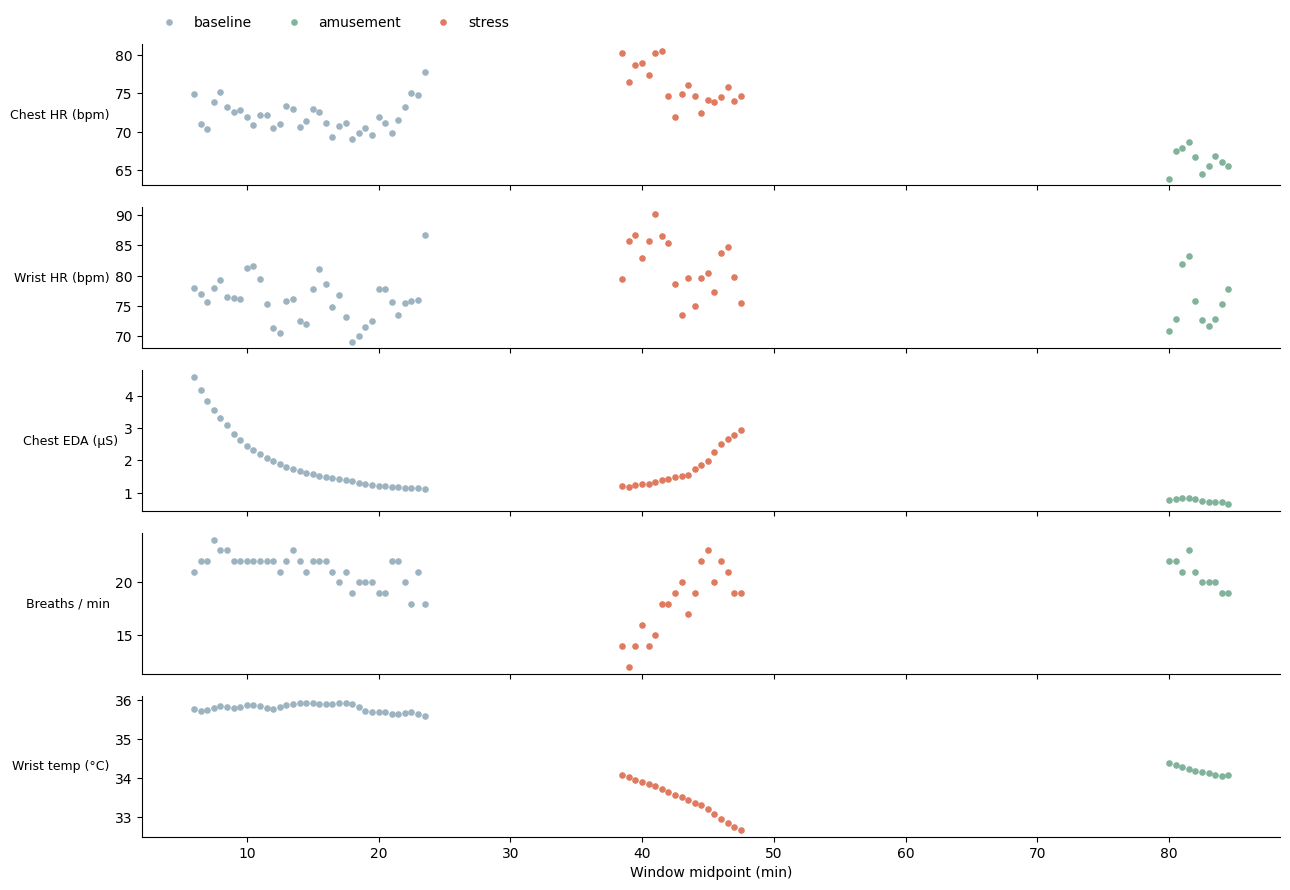

In [ ]:
# Plot selected window-level features over time, one panel per feature,

# ---- Choose which features to plot ------------------------------------------
# Each entry is (column name in `win`, y-axis label).
show = [
    ("chest_hr_bpm",  "Chest HR (bpm)"),
    ("wrist_hr_bpm",  "Wrist HR (bpm)"),
    ("chest_eda_uS",  "Chest EDA (µS)"),
    ("resp_rate_bpm", "Breaths / min"),
    ("wrist_temp_C",  "Wrist temp (°C)"),
]

# ---- Create the figure ------------------------------------------------------
# One row per feature; sharex=True so all panels share the same time axis

fig, axes = plt.subplots(len(show), 1, figsize=(13, 9), sharex=True)

for ax, (col, name) in zip(axes, show):

    # Draw one color group at a time. Order (1, 3, 2) is baseline, amusement,
    # stress, which also sets the legend order.
    for lab in (1, 3, 2):
        # Keep only windows from this condition.
        w = win[win["condition"] == LABEL_NAMES[lab]]

        # t_start_min is the window START; adding 0.5 min (half of the 60 s
        # window) places each dot at its midpoint, matching the x-axis label.
        ax.scatter(w["t_start_min"] + 0.5, w[col], s=14,
                   color=COLORS[lab], label=LABEL_NAMES[lab])

    # Horizontal label to the left of the panel so long names stay readable.
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)

# ---- Legend, axis label -----------------------------------------------------
axes[0].legend(frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.02))

axes[-1].set_xlabel("Window midpoint (min)")

fig.tight_layout()  # prevent labels and panels from overlapping
plt.show()

### Figure 4: feature distributions by condition

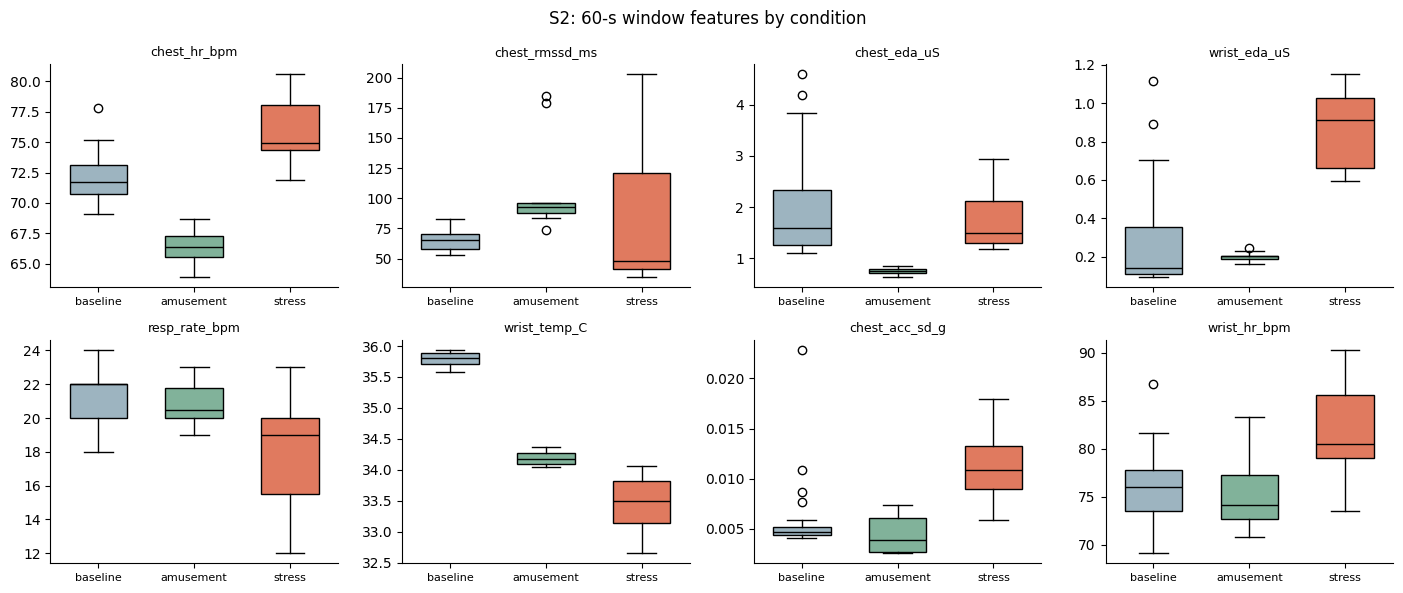

In [ ]:
# Compare the distribution of 8 window-level features across conditions.

# ---- Choose features and condition order ------------------------------------
box_feats = ["chest_hr_bpm", "chest_rmssd_ms", "chest_eda_uS", "wrist_eda_uS",
             "resp_rate_bpm", "wrist_temp_C", "chest_acc_sd_g", "wrist_hr_bpm"]

# Left-to-right order of the boxes in every panel.
order = ["baseline", "amusement", "stress"]

# ---- Create the figure ------------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(14, 6))

# axes is a 2D array; .ravel() flattens it so it pairs up with the feature list.
for ax, feat in zip(axes.ravel(), box_feats):

    # One array of values per condition
    # .dropna() removes windows where the feature is NaN (e.g. rejected
    # heart rate windows), since boxplot can't handle missing values.
    vals = [win.loc[win["condition"] == c, feat].dropna() for c in order]

    # patch_artist=True makes the boxes fillable
    # The median line is set to black so it stays visible on every color.
    bp = ax.boxplot(vals, patch_artist=True, widths=0.6,
                    medianprops={"color": "black"})

    # Color each box by condition.=
    for patch, lab in zip(bp["boxes"], (1, 3, 2)):
        patch.set_facecolor(COLORS[lab])

    # Boxplot positions start at 1, so ticks go at 1, 2, 3 with condition names.
    ax.set_xticks([1, 2, 3], order, fontsize=8)

    # The column name doubles as the panel title.
    ax.set_title(feat, fontsize=9)

fig.suptitle(f"{SUBJECT}: 60-s window features by condition")
fig.tight_layout()  # prevent titles and labels from overlapping
plt.show()